# CP3 - RELAÇÃO DE PESO E ARREMESSO
Pergunta central: Como o peso corporal cadastrado se associa ao tipo de arremesso realizado e ao aproveitamento dos jogadores, considerando também altura e temporada?

In [10]:
# Imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from IPython.display import display
from matplotlib.ticker import FuncFormatter, PercentFormatter

## 1. MÓDULO 1 - CARREGAMENTO E CONFERÊNCIA DA BASE DO CP3
- CARREGAMENTO DA BASE PREPARADA NO CP2

In [8]:
# 1. Localiza os arquivos exportados.

pasta_dados = Path("dados/cp3")

arquivo_base = (
    pasta_dados / "base_peso_arremessos.csv.gz"
)

arquivo_metadados = (
    pasta_dados / "metadados_base_peso.json"
)

for arquivo in [arquivo_base, arquivo_metadados]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {arquivo.resolve()}\n"
            "Execute primeiro a exportação no CP2 e confira "
            "a pasta de trabalho do CP3."
        )


# 2. Lê os metadados e carrega a base.

metadados_cp3 = json.loads(
    arquivo_metadados.read_text(encoding="utf-8")
)

df_cp3 = pd.read_csv(
    arquivo_base,
    dtype=metadados_cp3["tipos_dados"],
    encoding="utf-8"
)

if df_cp3.empty:
    raise ValueError("A base do CP3 está vazia.")

if df_cp3.columns.tolist() != metadados_cp3["colunas"]:
    raise ValueError(
        "As colunas não correspondem à exportação do CP2."
    )


# 3. Confere identificadores e duplicações.

chaves_evento = ["GAME_ID", "GAME_EVENT_ID"]
chaves_perfil = ["PLAYER_ID", "SEASON"]

if df_cp3[
    chaves_evento + chaves_perfil
].isna().any().any():
    raise ValueError(
        "Existem identificadores ausentes."
    )

if df_cp3.duplicated(chaves_evento).any():
    raise ValueError(
        "Existem eventos duplicados."
    )


# 4. Confere as medidas físicas e os perfis.

for coluna in ["PESO_KG", "ALTURA_CM"]:
    valores = df_cp3[coluna]

    if (~np.isfinite(valores) | valores.le(0)).any():
        raise ValueError(
            f"Existem medidas ausentes ou inválidas em {coluna}."
        )

medidas_por_perfil = (
    df_cp3
    .groupby(chaves_perfil)[["PESO_KG", "ALTURA_CM"]]
    .nunique()
)

if medidas_por_perfil.gt(1).any().any():
    raise ValueError(
        "Existem jogadores–temporadas com mais "
        "de um peso ou mais de uma altura."
    )


# 5. Confere resultados, tipos e distância.

if not df_cp3["SHOT_MADE_FLAG"].isin([0, 1]).all():
    raise ValueError(
        "Existem resultados ausentes ou diferentes de 0 e 1."
    )

tipos_esperados = [
    "Três pontos",
    "Bandejas",
    "Enterradas",
    "Outras tentativas"
]

if not df_cp3["TIPO_TENTATIVA"].isin(tipos_esperados).all():
    raise ValueError(
        "Existem classificações ausentes ou inesperadas."
    )

distancias = df_cp3["DISTANCIA_M"]

distancias_invalidas = (
    distancias.notna()
    & (~np.isfinite(distancias) | distancias.lt(0))
)

if distancias_invalidas.any():
    raise ValueError(
        "Existem distâncias negativas ou infinitas."
    )


# 6. Compara as contagens com a exportação.

contagens_cp3 = {
    "eventos": int(len(df_cp3)),
    "jogadores_distintos": int(
        df_cp3["PLAYER_ID"].nunique()
    ),
    "perfis_jogador_temporada": int(
        len(df_cp3[chaves_perfil].drop_duplicates())
    ),
    "acertos": int(
        df_cp3["SHOT_MADE_FLAG"].eq(1).sum()
    ),
    "erros": int(
        df_cp3["SHOT_MADE_FLAG"].eq(0).sum()
    ),
    "sem_distancia": int(
        df_cp3["DISTANCIA_M"].isna().sum()
    )
}

if contagens_cp3 != metadados_cp3["contagens"]:
    raise ValueError(
        "As contagens não correspondem à exportação do CP2."
    )

print("BASE CARREGADA E CONFERIDA")
print("Unidade de observação: uma tentativa de arremesso.")

print("\nCONFERÊNCIA — MÓDULO 1 DO CP3")

display(
    pd.DataFrame(
        contagens_cp3.items(),
        columns=["VERIFICAÇÃO", "QUANTIDADE"]
    )
)

print("\nAMOSTRA DA BASE")
display(df_cp3.head())

BASE CARREGADA E CONFERIDA
Unidade de observação: uma tentativa de arremesso.

CONFERÊNCIA — MÓDULO 1 DO CP3


,VERIFICAÇÃO,QUANTIDADE
0,eventos,2098123
1,jogadores_distintos,1441
2,perfis_jogador_temporada,5356
3,acertos,972907
4,erros,1125216
5,sem_distancia,341



AMOSTRA DA BASE


,GAME_ID,GAME_EVENT_ID,PLAYER_ID,SEASON,PESO_KG,ALTURA_CM,SHOT_MADE_FLAG,DISTANCIA_M,TIPO_TENTATIVA
0,0021500003,15,101106,2015-16,117.93,213.36,1,0.00,Bandejas
1,0021500003,34,101106,2015-16,117.93,213.36,1,0.00,Enterradas
2,0021500003,204,101106,2015-16,117.93,213.36,1,0.61,Bandejas
3,0021500003,233,101106,2015-16,117.93,213.36,1,0.30,Bandejas
4,0021500003,255,101106,2015-16,117.93,213.36,1,0.30,Bandejas


#### Conclusão do Output:
Exportação deu certo do CP2
- 2.098.123 tentativas;
- 1.441 jogadores, distribuídos em 5.356 perfis jogador–temporada;
- 972.907 acertos e 1.125.216 erros;
- 341 eventos sem distância, preservados.

## MÓDULO 2 - DISTRIBUIÇÃO E CONFERÊNCIA DO PESO
- Uma observação por jogador–temporada
- Não pondera o perfil pela quantidade de arremessos
- Sinaliza extremos pelo IQR, sem excluir registros
- Não altera df_cp3

RESUMO ESTATÍSTICO DO PESO — kg


,OBSERVAÇÕES,MÍNIMO,1º QUARTIL,MEDIANA,MÉDIA,3º QUARTIL,MÁXIMO,DESVIO PADRÃO
0,5.356,"68,04","90,72","97,52","98,40","106,59","141,07","11,16"



DISTRIBUIÇÃO POR FAIXAS DE PESO


,FAIXA (kg),PERFIS_JOGADOR_TEMPORADA,PERCENTUAL,PERCENTUAL_ACUMULADO
0,65 a <70,1,"0,02%","0,02%"
1,70 a <75,35,"0,65%","0,67%"
2,75 a <80,163,"3,04%","3,72%"
3,80 a <85,424,"7,92%","11,63%"
4,85 a <90,659,"12,30%","23,94%"
5,90 a <95,855,"15,96%","39,90%"
6,95 a <100,1.089,"20,33%","60,23%"
7,100 a <105,662,"12,36%","72,59%"
8,105 a <110,615,"11,48%","84,07%"
9,110 a <115,472,"8,81%","92,89%"



Limite inferior do IQR: 66,915 kg
Limite superior do IQR: 130,395 kg
Perfis sinalizados pelo IQR: 22


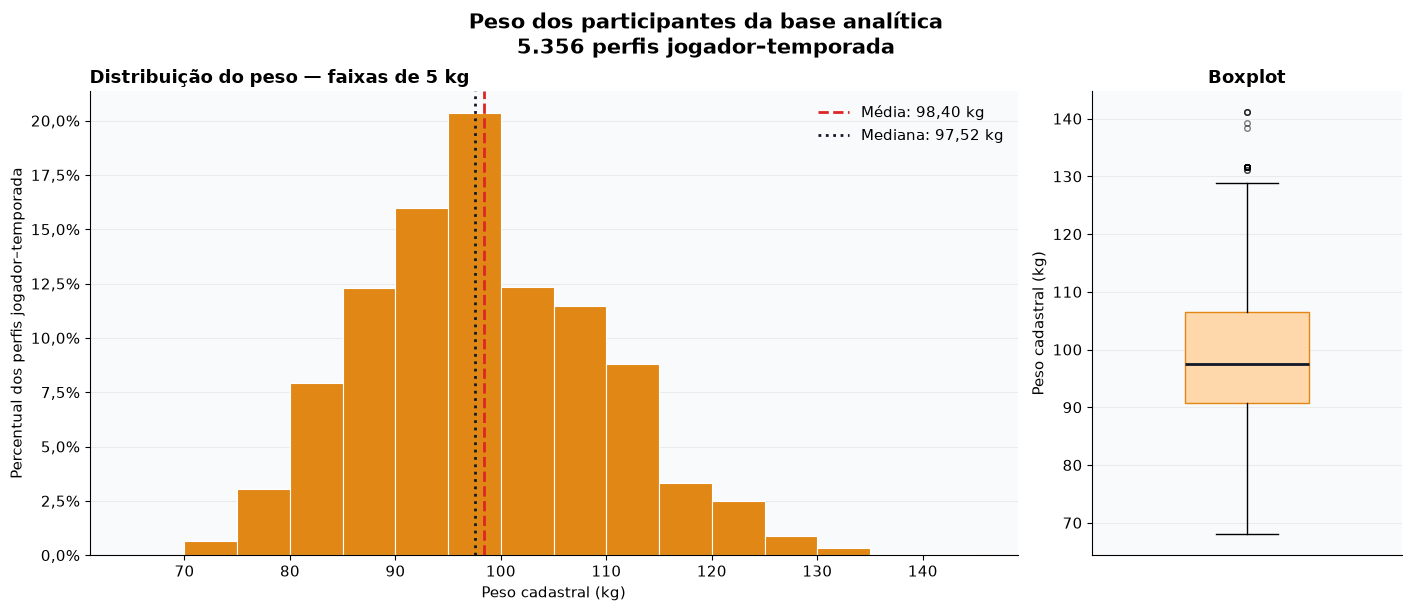


Imagem salva em: Z:\Documents\UFRN\TI\Período 6\CD\ciencias_de_dados_nba\graficos\cp3\peso\distribuicao_peso_perfis.png

Os pontos extremos do boxplot são alertas descritivos. Os registros permanecem na análise.
O mesmo jogador pode aparecer em várias temporadas. A distribuição não representa jogadores únicos.

CONFERÊNCIA — MÓDULO 2 DO CP3


,VERIFICAÇÃO,QUANTIDADE
0,Tentativas preservadas em df_cp3,2098123
1,Jogadores distintos,1441
2,Perfis jogador–temporada,5356
3,Perfis contabilizados nas faixas,5356
4,Perfis sinalizados pelo IQR,22
5,Perfis excluídos neste módulo,0


In [11]:
# 1. Confere a base e os perfis.

if "df_cp3" not in globals():
    raise RuntimeError(
        "Execute primeiro o módulo 1 do CP3."
    )

chaves_perfil = ["PLAYER_ID", "SEASON"]

colunas_necessarias = (
    chaves_perfil + ["PESO_KG", "ALTURA_CM"]
)

faltantes = set(colunas_necessarias) - set(df_cp3.columns)

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {sorted(faltantes)}"
    )

if df_cp3.empty:
    raise ValueError("A base está vazia.")

if df_cp3[chaves_perfil].isna().any().any():
    raise ValueError(
        "Existem eventos sem jogador ou temporada."
    )

# Verifica a consistência antes de retirar as repetições.
medidas_por_perfil = (
    df_cp3
    .groupby(chaves_perfil)[["PESO_KG", "ALTURA_CM"]]
    .nunique(dropna=False)
)

if medidas_por_perfil.gt(1).any().any():
    raise ValueError(
        "Existem jogadores–temporadas com mais "
        "de um peso ou mais de uma altura."
    )

perfis_cp3 = (
    df_cp3[colunas_necessarias]
    .drop_duplicates(subset=chaves_perfil)
    .copy()
)

pesos_cp3 = pd.to_numeric(
    perfis_cp3["PESO_KG"],
    errors="raise"
)

pesos_invalidos = (
    ~np.isfinite(pesos_cp3)
    | pesos_cp3.le(0)
)

if pesos_invalidos.any():
    raise ValueError(
        "Existem perfis com peso ausente ou inválido."
    )

perfis_cp3["PESO_KG"] = pesos_cp3


# 2. Calcula as estatísticas e os limites descritivos do IQR.

q1_peso_cp3 = pesos_cp3.quantile(0.25)
q3_peso_cp3 = pesos_cp3.quantile(0.75)

iqr_peso_cp3 = q3_peso_cp3 - q1_peso_cp3

limite_inferior_peso_cp3 = (
    q1_peso_cp3 - 1.5 * iqr_peso_cp3
)

limite_superior_peso_cp3 = (
    q3_peso_cp3 + 1.5 * iqr_peso_cp3
)

perfis_cp3["PESO_EXTREMO_IQR"] = (
    pesos_cp3.lt(limite_inferior_peso_cp3)
    | pesos_cp3.gt(limite_superior_peso_cp3)
)

perfis_peso_sinalizados_cp3 = perfis_cp3.loc[
    perfis_cp3["PESO_EXTREMO_IQR"]
].copy()

resumo_peso_cp3 = pd.DataFrame([{
    "OBSERVAÇÕES": len(perfis_cp3),
    "MÍNIMO": pesos_cp3.min(),
    "1º QUARTIL": q1_peso_cp3,
    "MEDIANA": pesos_cp3.median(),
    "MÉDIA": pesos_cp3.mean(),
    "3º QUARTIL": q3_peso_cp3,
    "MÁXIMO": pesos_cp3.max(),
    "DESVIO PADRÃO": pesos_cp3.std(ddof=1)
}])


# 3. Cria faixas de 5 kg para descrever a distribuição.
# Essas faixas ainda não definem os grupos das análises seguintes.

largura_faixa_peso = 5

inicio_peso = (
    np.floor(pesos_cp3.min() / largura_faixa_peso)
    * largura_faixa_peso
)

fim_peso = (
    np.floor(pesos_cp3.max() / largura_faixa_peso) + 1
) * largura_faixa_peso

limites_peso_cp3 = np.arange(
    inicio_peso,
    fim_peso + largura_faixa_peso / 2,
    largura_faixa_peso
)

contagens_peso_cp3, _ = np.histogram(
    pesos_cp3,
    bins=limites_peso_cp3
)

if int(contagens_peso_cp3.sum()) != len(perfis_cp3):
    raise ValueError(
        "As faixas não contabilizaram todos os perfis."
    )

percentuais_peso_cp3 = (
    contagens_peso_cp3 / len(perfis_cp3) * 100
)

if not np.isclose(percentuais_peso_cp3.sum(), 100):
    raise ValueError(
        "Os percentuais da distribuição não somam 100%."
    )

rotulos_peso_cp3 = [
    f"{inferior:.0f} a <{superior:.0f}"
    for inferior, superior in zip(
        limites_peso_cp3[:-1],
        limites_peso_cp3[1:]
    )
]

distribuicao_peso_cp3 = pd.DataFrame({
    "FAIXA (kg)": rotulos_peso_cp3,
    "PERFIS_JOGADOR_TEMPORADA": contagens_peso_cp3,
    "PERCENTUAL": percentuais_peso_cp3,
    "PERCENTUAL_ACUMULADO": percentuais_peso_cp3.cumsum()
})


# 4. Função de formatação.

def formatar_peso_cp3(valor, casas=2):
    return (
        f"{valor:,.{casas}f}"
        .replace(",", "_")
        .replace(".", ",")
        .replace("_", ".")
    )


# 5. Apresenta o resumo e a distribuição.
# Formata apenas as cópias exibidas.

resumo_visual = resumo_peso_cp3.copy()

for coluna in resumo_visual.columns:
    casas = 0 if coluna == "OBSERVAÇÕES" else 2

    resumo_visual[coluna] = resumo_visual[coluna].map(
        lambda valor, casas=casas: formatar_peso_cp3(valor, casas)
    )

print("RESUMO ESTATÍSTICO DO PESO — kg")
display(resumo_visual)

distribuicao_visual = distribuicao_peso_cp3.copy()

distribuicao_visual["PERFIS_JOGADOR_TEMPORADA"] = (
    distribuicao_visual["PERFIS_JOGADOR_TEMPORADA"].map(
        lambda valor: formatar_peso_cp3(valor, 0)
    )
)

for coluna in ["PERCENTUAL", "PERCENTUAL_ACUMULADO"]:
    distribuicao_visual[coluna] = (
        distribuicao_visual[coluna].map(
            lambda valor: f"{formatar_peso_cp3(valor)}%"
        )
    )

print("\nDISTRIBUIÇÃO POR FAIXAS DE PESO")
display(distribuicao_visual)

print(
    "\nLimite inferior do IQR:",
    formatar_peso_cp3(limite_inferior_peso_cp3, 3),
    "kg"
)

print(
    "Limite superior do IQR:",
    formatar_peso_cp3(limite_superior_peso_cp3, 3),
    "kg"
)

print(
    "Perfis sinalizados pelo IQR:",
    len(perfis_peso_sinalizados_cp3)
)


# 6. Gera o histograma e o boxplot.

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FAFC"
}):
    figura, eixos = plt.subplots(
        1,
        2,
        figsize=(14, 6),
        gridspec_kw={"width_ratios": [3, 1]},
        constrained_layout=True
    )

    eixo_histograma, eixo_boxplot = eixos

    eixo_histograma.bar(
        limites_peso_cp3[:-1],
        percentuais_peso_cp3,
        width=np.diff(limites_peso_cp3),
        align="edge",
        color="#E18716",
        edgecolor="white",
        linewidth=0.8
    )

    eixo_histograma.axvline(
        pesos_cp3.mean(),
        color="#DC2626",
        linestyle="--",
        linewidth=2,
        label=(
            f"Média: {formatar_peso_cp3(pesos_cp3.mean())} kg"
        )
    )

    eixo_histograma.axvline(
        pesos_cp3.median(),
        color="#111827",
        linestyle=":",
        linewidth=2,
        label=(
            f"Mediana: {formatar_peso_cp3(pesos_cp3.median())} kg"
        )
    )

    eixo_histograma.set_xlabel("Peso cadastral (kg)")
    eixo_histograma.set_ylabel(
        "Percentual dos perfis jogador–temporada"
    )

    eixo_histograma.set_title(
        "Distribuição do peso — faixas de 5 kg",
        loc="left",
        fontweight="bold"
    )

    eixo_histograma.yaxis.set_major_formatter(
        FuncFormatter(
            lambda valor, posicao: (
                f"{formatar_peso_cp3(valor, 1)}%"
            )
        )
    )

    eixo_histograma.legend(frameon=False)
    eixo_histograma.grid(axis="y", alpha=0.2)
    eixo_histograma.set_axisbelow(True)

    eixo_boxplot.boxplot(
        pesos_cp3.to_numpy(),
        whis=1.5,
        patch_artist=True,
        widths=0.4,
        boxprops={
            "facecolor": "#FED7AA",
            "edgecolor": "#E18716"
        },
        medianprops={
            "color": "#111827",
            "linewidth": 2
        },
        flierprops={
            "marker": "o",
            "markersize": 4,
            "alpha": 0.5
        }
    )

    eixo_boxplot.set_xticks([])
    eixo_boxplot.set_ylabel("Peso cadastral (kg)")
    eixo_boxplot.set_title("Boxplot", fontweight="bold")
    eixo_boxplot.grid(axis="y", alpha=0.2)
    eixo_boxplot.set_axisbelow(True)

    figura.suptitle(
        "Peso dos participantes da base analítica\n"
        f"{formatar_peso_cp3(len(perfis_cp3), 0)} "
        "perfis jogador–temporada",
        fontsize=15,
        fontweight="bold"
    )

    pasta_graficos_peso = Path("graficos/cp3/peso")
    pasta_graficos_peso.mkdir(
        parents=True,
        exist_ok=True
    )

    caminho_distribuicao_peso = (
        pasta_graficos_peso / "distribuicao_peso_perfis.png"
    )

    figura.savefig(
        caminho_distribuicao_peso,
        dpi=200,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(figura)

print(
    "\nImagem salva em:",
    caminho_distribuicao_peso.resolve()
)


# 7. Apresenta a conferência geral.

conferencia_peso_cp3 = pd.DataFrame({
    "VERIFICAÇÃO": [
        "Tentativas preservadas em df_cp3",
        "Jogadores distintos",
        "Perfis jogador–temporada",
        "Perfis contabilizados nas faixas",
        "Perfis sinalizados pelo IQR",
        "Perfis excluídos neste módulo"
    ],
    "QUANTIDADE": [
        len(df_cp3),
        perfis_cp3["PLAYER_ID"].nunique(),
        len(perfis_cp3),
        int(contagens_peso_cp3.sum()),
        len(perfis_peso_sinalizados_cp3),
        0
    ]
})

print(
    "\nOs pontos extremos do boxplot são alertas descritivos. "
    "Os registros permanecem na análise."
)

print(
    "O mesmo jogador pode aparecer em várias temporadas. "
    "A distribuição não representa jogadores únicos."
)

print("\nCONFERÊNCIA — MÓDULO 2 DO CP3")
display(conferencia_peso_cp3)

#### Conclusão do output
- Os 22 perfis sinalizados pelo IQR estão na extremidade superior. 
- o menor peso, 68,04 kg, já está acima do limite inferior de 66,915 kg. 
- os alertas correspondem a pesos acima de 130,395 kg.

## MÓDULO 3 - TENTATIVAS E ACERTOS POR JOGADOR–TEMPORADA E TIPO
Responder:
- Quantas tentativas realizou de cada tipo;
- Quantas acertou e errou;
- Qual foi a participação daquele tipo nas suas tentativas;
- Qual foi seu aproveitamento naquele tipo.

In [12]:
# 1. Confere as informações necessárias.

if "df_cp3" not in globals():
    raise RuntimeError(
        "Execute primeiro o módulo 1 do CP3."
    )

chaves_perfil = ["PLAYER_ID", "SEASON"]

colunas_necessarias = {
    "PLAYER_ID",
    "SEASON",
    "PESO_KG",
    "ALTURA_CM",
    "TIPO_TENTATIVA",
    "SHOT_MADE_FLAG",
    "DISTANCIA_M"
}

faltantes = colunas_necessarias - set(df_cp3.columns)

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {sorted(faltantes)}"
    )

if df_cp3.empty:
    raise ValueError("A base está vazia.")

if df_cp3[chaves_perfil].isna().any().any():
    raise ValueError(
        "Existem eventos sem jogador ou temporada."
    )

if not df_cp3["SHOT_MADE_FLAG"].isin([0, 1]).all():
    raise ValueError(
        "Existem resultados ausentes ou diferentes de 0 e 1."
    )

tipos_cp3 = [
    "Três pontos",
    "Bandejas",
    "Enterradas",
    "Outras tentativas"
]

if not df_cp3["TIPO_TENTATIVA"].isin(tipos_cp3).all():
    raise ValueError(
        "Existem classificações ausentes ou inesperadas."
    )


# 2. Separa os perfis físicos.
# Cada jogador–temporada deve ter um único peso e uma única altura.

perfis_resumo_cp3 = (
    df_cp3[
        chaves_perfil + ["PESO_KG", "ALTURA_CM"]
    ]
    .drop_duplicates()
    .copy()
)

if perfis_resumo_cp3.duplicated(chaves_perfil).any():
    raise ValueError(
        "Existem medidas físicas diferentes "
        "para o mesmo jogador–temporada."
    )


# 3. Calcula o total de eventos de cada jogador–temporada.

resumo_jogador_temporada_cp3 = (
    df_cp3
    .groupby(chaves_perfil, observed=True)
    .agg(
        TOTAL_TENTATIVAS_PERFIL=("SHOT_MADE_FLAG", "size"),
        TOTAL_ACERTOS_PERFIL=("SHOT_MADE_FLAG", "sum"),
        TOTAL_COM_DISTANCIA_PERFIL=("DISTANCIA_M", "count")
    )
    .reset_index()
    .merge(
        perfis_resumo_cp3,
        on=chaves_perfil,
        how="left",
        validate="one_to_one"
    )
)

resumo_jogador_temporada_cp3["TOTAL_ERROS_PERFIL"] = (
    resumo_jogador_temporada_cp3["TOTAL_TENTATIVAS_PERFIL"]
    - resumo_jogador_temporada_cp3["TOTAL_ACERTOS_PERFIL"]
)

resumo_jogador_temporada_cp3["TOTAL_SEM_DISTANCIA_PERFIL"] = (
    resumo_jogador_temporada_cp3["TOTAL_TENTATIVAS_PERFIL"]
    - resumo_jogador_temporada_cp3["TOTAL_COM_DISTANCIA_PERFIL"]
)


# 4. Calcula as tentativas e os acertos por tipo.

agregados_por_tipo_cp3 = (
    df_cp3
    .groupby(
        chaves_perfil + ["TIPO_TENTATIVA"],
        observed=True
    )
    .agg(
        TENTATIVAS=("SHOT_MADE_FLAG", "size"),
        ACERTOS=("SHOT_MADE_FLAG", "sum"),
        COM_DISTANCIA=("DISTANCIA_M", "count")
    )
    .reset_index()
)


# 5. Cria quatro linhas para cada perfil.
# A grade inclui os tipos que o jogador não realizou.

grade_perfil_tipo_cp3 = resumo_jogador_temporada_cp3.merge(
    pd.DataFrame({"TIPO_TENTATIVA": tipos_cp3}),
    how="cross"
)

resumo_perfil_tipo_cp3 = grade_perfil_tipo_cp3.merge(
    agregados_por_tipo_cp3,
    on=chaves_perfil + ["TIPO_TENTATIVA"],
    how="left",
    validate="one_to_one"
)

# Ausência na agregação significa que não houve eventos daquele tipo.
# Somente as contagens recebem zero.
for coluna in ["TENTATIVAS", "ACERTOS", "COM_DISTANCIA"]:
    resumo_perfil_tipo_cp3[coluna] = (
        resumo_perfil_tipo_cp3[coluna]
        .fillna(0)
        .astype("int64")
    )

resumo_perfil_tipo_cp3["ERROS"] = (
    resumo_perfil_tipo_cp3["TENTATIVAS"]
    - resumo_perfil_tipo_cp3["ACERTOS"]
)

resumo_perfil_tipo_cp3["SEM_DISTANCIA"] = (
    resumo_perfil_tipo_cp3["TENTATIVAS"]
    - resumo_perfil_tipo_cp3["COM_DISTANCIA"]
)


# 6. Calcula composição e aproveitamento.
# Os denominadores são diferentes.

resumo_perfil_tipo_cp3["PARTICIPACAO_TIPO_PCT"] = (
    100
    * resumo_perfil_tipo_cp3["TENTATIVAS"]
    / resumo_perfil_tipo_cp3["TOTAL_TENTATIVAS_PERFIL"]
)

# Substitui o denominador zero por NaN.
# Isso mantém o aproveitamento ausente quando não houve tentativas.
denominador_aproveitamento = (
    resumo_perfil_tipo_cp3["TENTATIVAS"]
    .replace(0, np.nan)
)

resumo_perfil_tipo_cp3["APROVEITAMENTO_PCT"] = (
    100
    * resumo_perfil_tipo_cp3["ACERTOS"]
    / denominador_aproveitamento
)


# 7. Confere os resultados.

if len(resumo_perfil_tipo_cp3) != 4 * len(perfis_resumo_cp3):
    raise ValueError(
        "A tabela não possui quatro linhas por perfil."
    )

if (
    resumo_perfil_tipo_cp3["ACERTOS"]
    > resumo_perfil_tipo_cp3["TENTATIVAS"]
).any():
    raise ValueError(
        "Existem mais acertos do que tentativas."
    )

participacao_por_perfil = (
    resumo_perfil_tipo_cp3
    .groupby(chaves_perfil)["PARTICIPACAO_TIPO_PCT"]
    .sum()
)

if not np.allclose(participacao_por_perfil, 100):
    raise ValueError(
        "A composição das tentativas não soma 100% por perfil."
    )

sem_tentativas = resumo_perfil_tipo_cp3["TENTATIVAS"].eq(0)

if resumo_perfil_tipo_cp3.loc[
    sem_tentativas,
    "APROVEITAMENTO_PCT"
].notna().any():
    raise ValueError(
        "Há aproveitamento calculado para tipos sem tentativas."
    )

total_tentativas_agregado = int(
    resumo_perfil_tipo_cp3["TENTATIVAS"].sum()
)

total_acertos_agregado = int(
    resumo_perfil_tipo_cp3["ACERTOS"].sum()
)

total_erros_agregado = int(
    resumo_perfil_tipo_cp3["ERROS"].sum()
)

total_sem_distancia_agregado = int(
    resumo_perfil_tipo_cp3["SEM_DISTANCIA"].sum()
)

if total_tentativas_agregado != len(df_cp3):
    raise ValueError(
        "A agregação alterou a quantidade total de tentativas."
    )

if total_acertos_agregado != int(
    df_cp3["SHOT_MADE_FLAG"].eq(1).sum()
):
    raise ValueError(
        "A agregação alterou a quantidade total de acertos."
    )

if total_erros_agregado != int(
    df_cp3["SHOT_MADE_FLAG"].eq(0).sum()
):
    raise ValueError(
        "A agregação alterou a quantidade total de erros."
    )

if total_sem_distancia_agregado != int(
    df_cp3["DISTANCIA_M"].isna().sum()
):
    raise ValueError(
        "A agregação alterou a quantidade de eventos sem distância."
    )


# 8. Apresenta uma amostra da tabela.
# Mantém as taxas com precisão completa na tabela original.

colunas_amostra = [
    "PLAYER_ID",
    "SEASON",
    "PESO_KG",
    "ALTURA_CM",
    "TIPO_TENTATIVA",
    "TENTATIVAS",
    "ACERTOS",
    "ERROS",
    "TOTAL_TENTATIVAS_PERFIL",
    "PARTICIPACAO_TIPO_PCT",
    "APROVEITAMENTO_PCT"
]

print("AMOSTRA — RESUMO POR PERFIL E TIPO")

with pd.option_context(
    "display.max_columns", None,
    "display.float_format", "{:.2f}".format
):
    display(
        resumo_perfil_tipo_cp3[colunas_amostra].head(8)
    )


# 9. Apresenta a conferência geral.

conferencia_modulo3_cp3 = pd.DataFrame({
    "VERIFICAÇÃO": [
        "Perfis jogador–temporada",
        "Linhas na tabela por perfil e tipo",
        "Tentativas na base original",
        "Tentativas contabilizadas na agregação",
        "Acertos contabilizados",
        "Erros contabilizados",
        "Eventos sem distância contabilizados",
        "Combinações perfil–tipo sem tentativas"
    ],
    "QUANTIDADE": [
        len(perfis_resumo_cp3),
        len(resumo_perfil_tipo_cp3),
        len(df_cp3),
        total_tentativas_agregado,
        total_acertos_agregado,
        total_erros_agregado,
        total_sem_distancia_agregado,
        int(sem_tentativas.sum())
    ]
})

print("\nCONFERÊNCIA — MÓDULO 3 DO CP3")
display(conferencia_modulo3_cp3)

print(
    "\nPARTICIPACAO_TIPO_PCT: percentual das tentativas "
    "do perfil que corresponde àquele tipo."
)

print(
    "APROVEITAMENTO_PCT: percentual das tentativas "
    "daquele tipo que foi convertido."
)

print(
    "Zero tentativas gera aproveitamento ausente. "
    "Tentativas realizadas sem nenhum acerto geram aproveitamento zero."
)

AMOSTRA — RESUMO POR PERFIL E TIPO


,PLAYER_ID,SEASON,PESO_KG,ALTURA_CM,TIPO_TENTATIVA,TENTATIVAS,ACERTOS,ERROS,TOTAL_TENTATIVAS_PERFIL,PARTICIPACAO_TIPO_PCT,APROVEITAMENTO_PCT
0,101106,2015-16,117.93,213.36,Três pontos,1,1,0,279,0.36,100.00
1,101106,2015-16,117.93,213.36,Bandejas,98,59,39,279,35.13,60.20
2,101106,2015-16,117.93,213.36,Enterradas,85,80,5,279,30.47,94.12
3,101106,2015-16,117.93,213.36,Outras tentativas,95,35,60,279,34.05,36.84
4,101106,2016-17,117.93,213.36,Três pontos,1,0,1,81,1.23,0.00
5,101106,2016-17,117.93,213.36,Bandejas,33,16,17,81,40.74,48.48
6,101106,2016-17,117.93,213.36,Enterradas,8,7,1,81,9.88,87.50
7,101106,2016-17,117.93,213.36,Outras tentativas,39,15,24,81,48.15,38.46



CONFERÊNCIA — MÓDULO 3 DO CP3


,VERIFICAÇÃO,QUANTIDADE
0,Perfis jogador–temporada,5356
1,Linhas na tabela por perfil e tipo,21424
2,Tentativas na base original,2098123
3,Tentativas contabilizadas na agregação,2098123
4,Acertos contabilizados,972907
5,Erros contabilizados,1125216
6,Eventos sem distância contabilizados,341
7,Combinações perfil–tipo sem tentativas,1700



PARTICIPACAO_TIPO_PCT: percentual das tentativas do perfil que corresponde àquele tipo.
APROVEITAMENTO_PCT: percentual das tentativas daquele tipo que foi convertido.
Zero tentativas gera aproveitamento ausente. Tentativas realizadas sem nenhum acerto geram aproveitamento zero.


O jogador acertou sua única tentativa de três pontos. Portanto, o aproveitamento de 100% está matematicamente correto, mas uma tentativa oferece pouca informação para avaliar seu desempenho nesse tipo.

Nas bandejas, foram 98 tentativas e 59 acertos: elas representaram 35,13% do repertório observado, com aproveitamento de 60,20%.

As 1.700 combinações sem tentativas também estão corretas.

## MÓDULO 4 - FAIXAS DE PESO E COMPOSIÇÃO DAS TENTATIVAS
- Usaremos os quartis encontrados no módulo 2 para formar quatro faixas. Pesos iguais permanecerão juntos, por isso os grupos podem ter quantidades um pouco diferentes de perfis.
- Vamos comparar duas perspectivas:
    - volume de tentativas: A composição de todos os eventos do grupo; quem arremessou mais contribui mais
    - média dos perfis: A média das participações individuais; cada jogador–temporada contribui uma vez

RESUMO DAS FAIXAS DE PESO


,GRUPO_PESO,INTERVALO,PERFIS_JOGADOR_TEMPORADA,JOGADORES_DISTINTOS,TENTATIVAS
0,Faixa 1,"Até 90,72 kg",1.568,489,636.630
1,Faixa 2,">90,72 até 97,52 kg",1.226,379,463.003
2,Faixa 3,">97,52 até 106,59 kg",1.321,392,515.259
3,Faixa 4,"Acima de 106,59 kg",1.241,318,483.231



COMPOSIÇÃO PELO VOLUME DE TENTATIVAS (%)


TIPO_TENTATIVA,Três pontos,Bandejas,Enterradas,Outras tentativas
GRUPO_PESO,,,,
Faixa 1,"41,72%","24,23%","1,94%","32,11%"
Faixa 2,"44,15%","25,33%","4,38%","26,14%"
Faixa 3,"38,37%","26,37%","5,98%","29,28%"
Faixa 4,"21,49%","31,57%","11,27%","35,67%"



COMPOSIÇÃO MÉDIA DOS PERFIS (%)


TIPO_TENTATIVA,Três pontos,Bandejas,Enterradas,Outras tentativas
GRUPO_PESO,,,,
Faixa 1,"43,17%","24,97%","2,47%","29,39%"
Faixa 2,"45,21%","25,94%","5,10%","23,75%"
Faixa 3,"38,42%","28,38%","7,34%","25,86%"
Faixa 4,"21,49%","33,85%","13,04%","31,62%"


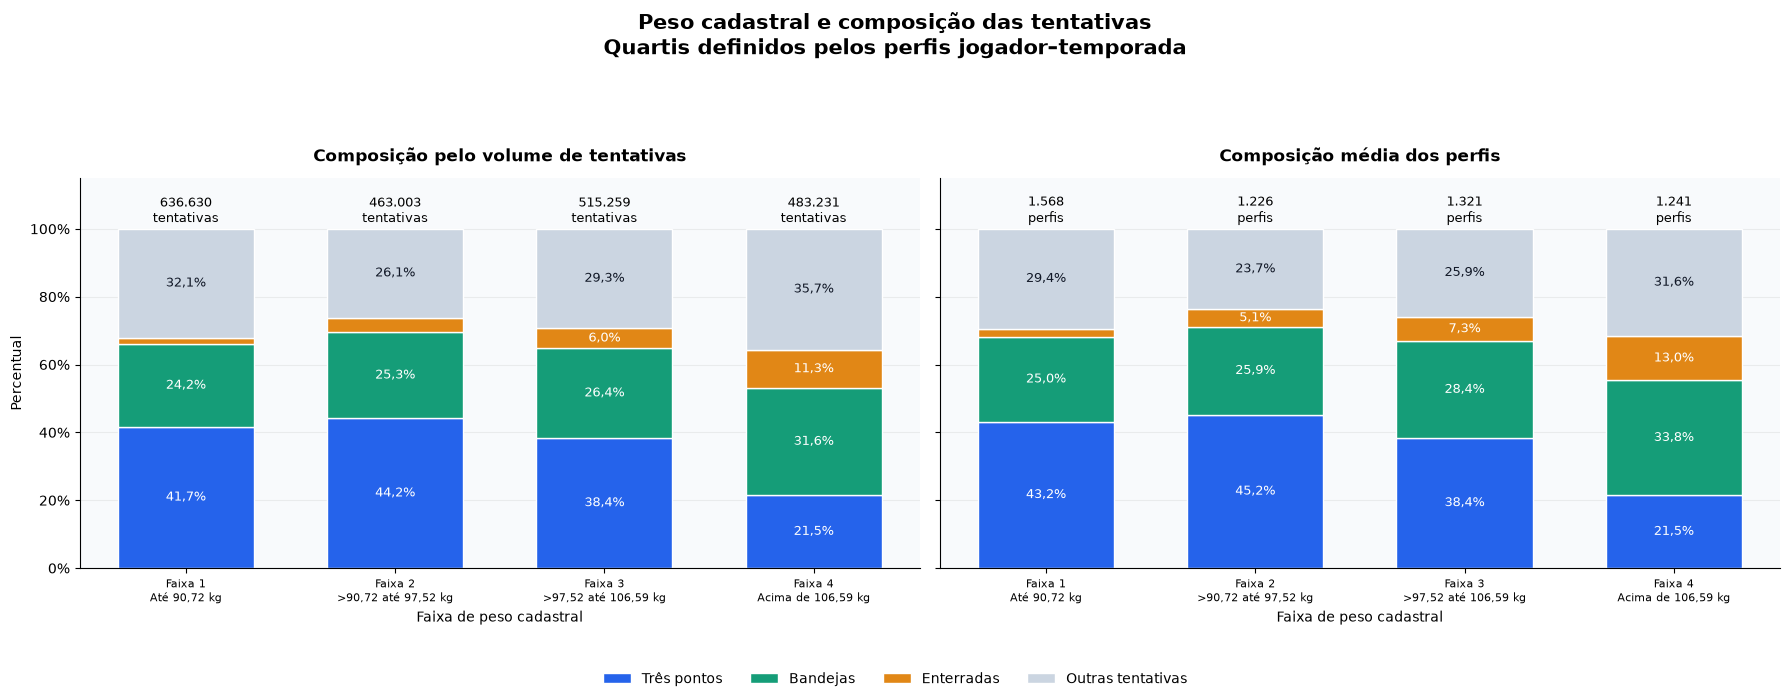

Imagem salva em: Z:\Documents\UFRN\TI\Período 6\CD\ciencias_de_dados_nba\graficos\cp3\peso\composicao_tentativas_faixas_peso.png

Tentativas contabilizadas: 2.098.123
Perfis contabilizados: 5.356
Pesos iguais permanecem na mesma faixa; os grupos podem ter quantidades diferentes de perfis.
Um jogador pode aparecer em faixas diferentes em temporadas distintas.
Nenhum perfil foi excluído. Esta comparação inicial é descritiva; altura e temporada serão consideradas nas etapas seguintes.


In [13]:
# 1. Confere a execução dos módulos anteriores.

necessarias = [
    "df_cp3",
    "resumo_jogador_temporada_cp3",
    "resumo_perfil_tipo_cp3"
]

faltantes = [
    nome for nome in necessarias
    if nome not in globals()
]

if faltantes:
    raise RuntimeError(
        "Execute os módulos anteriores. "
        f"Variáveis ausentes: {faltantes}"
    )

chaves_perfil = ["PLAYER_ID", "SEASON"]

tipos_peso_cp3 = [
    "Três pontos",
    "Bandejas",
    "Enterradas",
    "Outras tentativas"
]

grupos_peso_cp3 = [
    "Faixa 1",
    "Faixa 2",
    "Faixa 3",
    "Faixa 4"
]


# 2. Obtém uma observação física por jogador–temporada.

perfis_faixas_peso_cp3 = resumo_jogador_temporada_cp3[
    chaves_perfil + ["PESO_KG", "ALTURA_CM"]
].copy()

if perfis_faixas_peso_cp3.duplicated(chaves_perfil).any():
    raise ValueError(
        "Existem perfis jogador–temporada duplicados."
    )

pesos = pd.to_numeric(
    perfis_faixas_peso_cp3["PESO_KG"],
    errors="raise"
)

if (~np.isfinite(pesos) | pesos.le(0)).any():
    raise ValueError(
        "Existem pesos ausentes ou inválidos."
    )


# 3. Define as faixas pelos quartis.
# A distribuição usada é a dos perfis, não a dos eventos.

cortes_peso_cp3 = pesos.quantile(
    [0.25, 0.50, 0.75]
).to_numpy()

q1_peso, mediana_peso, q3_peso = cortes_peso_cp3

if not (q1_peso < mediana_peso < q3_peso):
    raise ValueError(
        "Os quartis não fornecem três cortes distintos. "
        "O agrupamento precisa ser revisto."
    )

perfis_faixas_peso_cp3["GRUPO_PESO"] = pd.cut(
    pesos,
    bins=[
        -np.inf,
        q1_peso,
        mediana_peso,
        q3_peso,
        np.inf
    ],
    labels=grupos_peso_cp3,
    right=True
)

if perfis_faixas_peso_cp3["GRUPO_PESO"].isna().any():
    raise ValueError(
        "Existem perfis sem faixa de peso."
    )


def numero_faixas_peso(valor, casas=2):
    return (
        f"{valor:,.{casas}f}"
        .replace(",", "_")
        .replace(".", ",")
        .replace("_", ".")
    )


rotulos_faixas_peso_cp3 = {
    "Faixa 1": (
        f"Até {numero_faixas_peso(q1_peso)} kg"
    ),
    "Faixa 2": (
        f">{numero_faixas_peso(q1_peso)} "
        f"até {numero_faixas_peso(mediana_peso)} kg"
    ),
    "Faixa 3": (
        f">{numero_faixas_peso(mediana_peso)} "
        f"até {numero_faixas_peso(q3_peso)} kg"
    ),
    "Faixa 4": (
        f"Acima de {numero_faixas_peso(q3_peso)} kg"
    )
}


# 4. Associa as faixas à tabela de perfis e tipos.

if resumo_perfil_tipo_cp3.duplicated(
    chaves_perfil + ["TIPO_TENTATIVA"]
).any():
    raise ValueError(
        "Existem combinações perfil–tipo duplicadas."
    )

if not resumo_perfil_tipo_cp3["TIPO_TENTATIVA"].isin(
    tipos_peso_cp3
).all():
    raise ValueError(
        "Existem tipos de tentativa inesperados."
    )

linhas_por_perfil = (
    resumo_perfil_tipo_cp3
    .groupby(chaves_perfil)
    .size()
)

if not linhas_por_perfil.eq(4).all():
    raise ValueError(
        "Cada perfil deve possuir os quatro tipos de tentativa."
    )

base_composicao_peso_cp3 = resumo_perfil_tipo_cp3.merge(
    perfis_faixas_peso_cp3[
        chaves_perfil + ["GRUPO_PESO"]
    ],
    on=chaves_perfil,
    how="left",
    validate="many_to_one",
    indicator=True
)

if base_composicao_peso_cp3["_merge"].ne("both").any():
    raise ValueError(
        "Existem perfis sem correspondência nas faixas de peso."
    )

base_composicao_peso_cp3 = (
    base_composicao_peso_cp3.drop(columns="_merge")
)


# 5. Perspectiva 1: composição pelo volume de tentativas.
# Soma as tentativas de cada tipo dentro da faixa.

contagens_faixas_peso_cp3 = (
    base_composicao_peso_cp3
    .groupby(
        ["GRUPO_PESO", "TIPO_TENTATIVA"],
        observed=True
    )["TENTATIVAS"]
    .sum()
    .unstack(fill_value=0)
    .reindex(
        index=grupos_peso_cp3,
        columns=tipos_peso_cp3,
        fill_value=0
    )
)

totais_tentativas_faixas_cp3 = (
    contagens_faixas_peso_cp3.sum(axis=1)
)

if totais_tentativas_faixas_cp3.eq(0).any():
    raise ValueError(
        "Alguma faixa não possui tentativas."
    )

composicao_volume_peso_cp3 = (
    contagens_faixas_peso_cp3
    .div(totais_tentativas_faixas_cp3, axis=0)
    .mul(100)
)


# 6. Perspectiva 2: composição média dos perfis.
# Cada jogador–temporada contribui uma vez para cada tipo.
# Inclui participação zero nos tipos que o perfil não realizou.

if base_composicao_peso_cp3[
    "PARTICIPACAO_TIPO_PCT"
].isna().any():
    raise ValueError(
        "Existem participações individuais ausentes."
    )

composicao_media_perfis_peso_cp3 = (
    base_composicao_peso_cp3
    .groupby(
        ["GRUPO_PESO", "TIPO_TENTATIVA"],
        observed=True
    )["PARTICIPACAO_TIPO_PCT"]
    .mean()
    .unstack()
    .reindex(
        index=grupos_peso_cp3,
        columns=tipos_peso_cp3
    )
)


# 7. Confere a conservação dos eventos e dos percentuais.

total_contabilizado = int(
    contagens_faixas_peso_cp3.to_numpy().sum()
)

if total_contabilizado != len(df_cp3):
    raise ValueError(
        "As faixas não contabilizaram todas as tentativas."
    )

for nome, tabela in [
    ("Volume", composicao_volume_peso_cp3),
    ("Média dos perfis", composicao_media_perfis_peso_cp3)
]:
    if tabela.isna().any().any():
        raise ValueError(
            f"{nome}: existem resultados ausentes."
        )

    if not np.allclose(tabela.sum(axis=1), 100):
        raise ValueError(
            f"{nome}: os percentuais não somam 100% por faixa."
        )


# 8. Resume os participantes e o volume de cada faixa.

quantidade_perfis_faixas_cp3 = (
    perfis_faixas_peso_cp3
    .groupby("GRUPO_PESO", observed=True)
    .size()
    .reindex(grupos_peso_cp3, fill_value=0)
)

quantidade_jogadores_faixas_cp3 = (
    perfis_faixas_peso_cp3
    .groupby("GRUPO_PESO", observed=True)["PLAYER_ID"]
    .nunique()
    .reindex(grupos_peso_cp3, fill_value=0)
)

if int(quantidade_perfis_faixas_cp3.sum()) != len(
    perfis_faixas_peso_cp3
):
    raise ValueError(
        "As faixas não contabilizaram todos os perfis."
    )

resumo_faixas_peso_cp3 = pd.DataFrame({
    "INTERVALO": [
        rotulos_faixas_peso_cp3[grupo]
        for grupo in grupos_peso_cp3
    ],
    "PERFIS_JOGADOR_TEMPORADA": quantidade_perfis_faixas_cp3,
    "JOGADORES_DISTINTOS": quantidade_jogadores_faixas_cp3,
    "TENTATIVAS": totais_tentativas_faixas_cp3
})

resumo_faixas_peso_cp3.index.name = "GRUPO_PESO"


# 9. Exibe cópias formatadas das tabelas.

resumo_visual = resumo_faixas_peso_cp3.reset_index().copy()

for coluna in [
    "PERFIS_JOGADOR_TEMPORADA",
    "JOGADORES_DISTINTOS",
    "TENTATIVAS"
]:
    resumo_visual[coluna] = resumo_visual[coluna].map(
        lambda valor: numero_faixas_peso(valor, 0)
    )

print("RESUMO DAS FAIXAS DE PESO")
display(resumo_visual)


def exibir_composicao_peso(titulo, tabela):
    visual = tabela.copy()
    visual.index.name = "GRUPO_PESO"

    for coluna in visual.columns:
        visual[coluna] = visual[coluna].map(
            lambda valor: f"{numero_faixas_peso(valor)}%"
        )

    print(f"\n{titulo}")
    display(visual)


exibir_composicao_peso(
    "COMPOSIÇÃO PELO VOLUME DE TENTATIVAS (%)",
    composicao_volume_peso_cp3
)

exibir_composicao_peso(
    "COMPOSIÇÃO MÉDIA DOS PERFIS (%)",
    composicao_media_perfis_peso_cp3
)


# 10. Gera gráficos com escalas e cores comuns.

cores_tipos_peso_cp3 = {
    "Três pontos": "#2563EB",
    "Bandejas": "#159D78",
    "Enterradas": "#E18716",
    "Outras tentativas": "#CBD5E1"
}

configuracoes_composicao = [
    (
        "Composição pelo volume de tentativas",
        composicao_volume_peso_cp3,
        totais_tentativas_faixas_cp3,
        "tentativas"
    ),
    (
        "Composição média dos perfis",
        composicao_media_perfis_peso_cp3,
        quantidade_perfis_faixas_cp3,
        "perfis"
    )
]

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FAFC"
}):
    figura, eixos = plt.subplots(
        1,
        2,
        figsize=(18, 7),
        sharey=True
    )

    for eixo, (titulo, tabela, quantidades, unidade) in zip(
        eixos,
        configuracoes_composicao
    ):
        posicoes = np.arange(len(grupos_peso_cp3))
        acumulado = np.zeros(len(grupos_peso_cp3))

        for tipo in tipos_peso_cp3:
            valores = tabela[tipo].to_numpy()

            eixo.bar(
                posicoes,
                valores,
                bottom=acumulado,
                color=cores_tipos_peso_cp3[tipo],
                edgecolor="white",
                width=0.65,
                label=tipo
            )

            for posicao, percentual, base in zip(
                posicoes,
                valores,
                acumulado
            ):
                if percentual >= 5:
                    eixo.text(
                        posicao,
                        base + percentual / 2,
                        f"{numero_faixas_peso(percentual, 1)}%",
                        ha="center",
                        va="center",
                        fontsize=9,
                        color=(
                            "#111827"
                            if tipo == "Outras tentativas"
                            else "white"
                        )
                    )

            acumulado += valores

        for posicao, grupo in enumerate(grupos_peso_cp3):
            eixo.text(
                posicao,
                102,
                f"{numero_faixas_peso(quantidades.loc[grupo], 0)}"
                f"\n{unidade}",
                ha="center",
                fontsize=9
            )

        eixo.set_xticks(posicoes)

        eixo.set_xticklabels(
            [
                f"{grupo}\n{rotulos_faixas_peso_cp3[grupo]}"
                for grupo in grupos_peso_cp3
            ],
            fontsize=8
        )

        eixo.set_ylim(0, 115)
        eixo.set_yticks(np.arange(0, 101, 20))
        eixo.yaxis.set_major_formatter(
            PercentFormatter(xmax=100)
        )

        eixo.set_title(
            titulo,
            fontweight="bold",
            pad=12
        )

        eixo.set_xlabel("Faixa de peso cadastral")
        eixo.grid(axis="y", alpha=0.2)
        eixo.set_axisbelow(True)

    eixos[0].set_ylabel("Percentual")

    identificadores, legendas = (
        eixos[0].get_legend_handles_labels()
    )

    figura.legend(
        identificadores,
        legendas,
        loc="lower center",
        ncol=4,
        frameon=False
    )

    figura.suptitle(
        "Peso cadastral e composição das tentativas\n"
        "Quartis definidos pelos perfis jogador–temporada",
        fontsize=15,
        fontweight="bold"
    )

    figura.tight_layout(rect=[0, 0.08, 1, 0.90])

    pasta_graficos = Path("graficos/cp3/peso")
    pasta_graficos.mkdir(parents=True, exist_ok=True)

    caminho_grafico = (
        pasta_graficos / "composicao_tentativas_faixas_peso.png"
    )

    figura.savefig(
        caminho_grafico,
        dpi=200,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(figura)

print("Imagem salva em:", caminho_grafico.resolve())

print(
    "\nTentativas contabilizadas:",
    numero_faixas_peso(total_contabilizado, 0)
)

print(
    "Perfis contabilizados:",
    numero_faixas_peso(len(perfis_faixas_peso_cp3), 0)
)

print(
    "Pesos iguais permanecem na mesma faixa; "
    "os grupos podem ter quantidades diferentes de perfis."
)

print(
    "Um jogador pode aparecer em faixas diferentes "
    "em temporadas distintas."
)

print(
    "Nenhum perfil foi excluído. "
    "Esta comparação inicial é descritiva; altura e temporada "
    "serão consideradas nas etapas seguintes."
)

#### Conclusão do módulo 4 - Composição das tentativas por faixa de peso

- As quatro faixas de peso somaram 5.356 perfis jogador-temporada e 2.098.123 tentativas. Os grupos ficaram com quantidades diferentes porque os jogadores com o mesmo peso foram mantidos juntos nos limites dos quartis.

- Na média por jogador-temporada, as bandejas e as enterradas tiveram uma participação maior conforme aumentou a faixa de peso. Comparando a primeira faixa (até 90,72 kg) com a última (acima de 106,59 kg), as bandejas passaram de 24,97% para 33,85%, enquanto as enterradas subiram de 2,47% para 13,04%.

- Já os arremessos de três pontos seguiram outro comportamento. A maior participação apareceu na segunda faixa, com 45,21%, e depois foi diminuindo nas duas faixas seguintes, chegando a 21,49% na última. Quando analisamos o volume total de tentativas, encontramos os mesmos padrões. Isso mostra que as diferenças entre as faixas também aparecem quando todos os perfis têm o mesmo peso na análise.

- Esses resultados mostram como as tentativas estão distribuídas entre os tipos de arremesso. Na próxima etapa, vamos comparar o aproveitamento em cada tipo. Depois, vamos considerar também a altura e a temporada para verificar se essas diferenças entre as faixas de peso continuam aparecendo quando comparamos perfis semelhantes.

## MÓDULO 5 - APROVEITAMENTO POR FAIXA DE PESO E TIPO

APROVEITAMENTO POR FAIXA DE PESO E TIPO


,FAIXA,TIPO,TENTATIVAS,ACERTOS,PERFIS QUE TENTARAM,PERFIS SEM TENTATIVAS,PELO VOLUME,MÉDIA DOS PERFIS
0,Faixa 1,Três pontos,265.587,96.248,1.543,25,"36,24%","32,42%"
1,Faixa 1,Bandejas,154.277,84.660,1.509,59,"54,88%","52,55%"
2,Faixa 1,Enterradas,12.324,10.759,957,611,"87,30%","84,42%"
3,Faixa 1,Outras tentativas,204.442,86.986,1.516,52,"42,55%","38,92%"
4,Faixa 2,Três pontos,204.430,73.486,1.209,17,"35,95%","32,47%"
5,Faixa 2,Bandejas,117.282,64.783,1.190,36,"55,24%","54,25%"
6,Faixa 2,Enterradas,20.278,17.943,999,227,"88,49%","86,74%"
7,Faixa 2,Outras tentativas,121.013,49.638,1.187,39,"41,02%","38,10%"
8,Faixa 3,Três pontos,197.713,71.185,1.262,59,"36,00%","31,28%"
9,Faixa 3,Bandejas,135.898,76.175,1.285,36,"56,05%","54,39%"


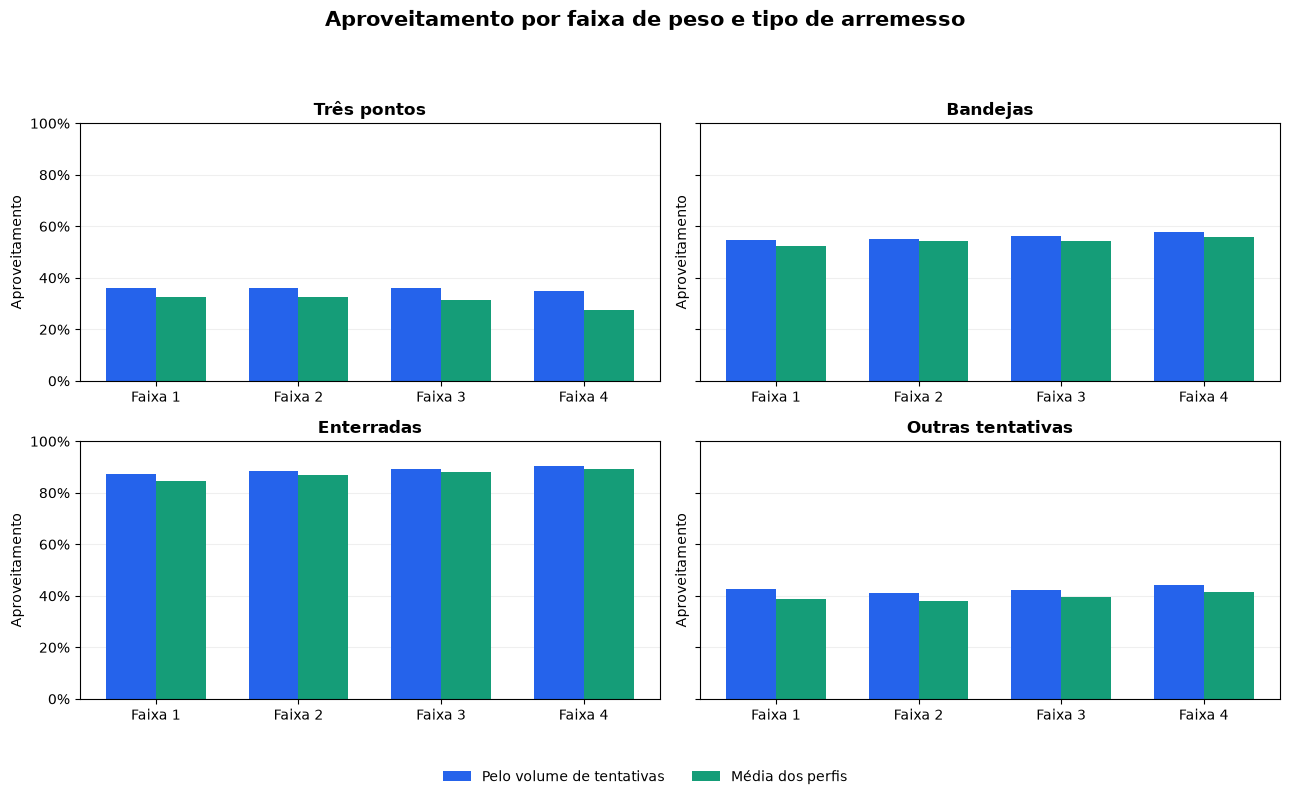

Imagem salva em: Z:\Documents\UFRN\TI\Período 6\CD\ciencias_de_dados_nba\graficos\cp3\peso\aproveitamento_faixas_peso.png

CONFERÊNCIA — MÓDULO 5 DO CP3


,VERIFICAÇÃO,QUANTIDADE
0,Combinações de faixa e tipo,16
1,Tentativas contabilizadas,2098123
2,Acertos contabilizados,972907
3,Erros contabilizados,1125216
4,Combinações perfil–tipo sem tentativas,1700


In [14]:

# Usa as faixas definidas no módulo 4.
# Aproveitamento pelo volume: total de acertos / total de tentativas.
# Média dos perfis: média das taxas dos perfis que tentaram o tipo.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter
from IPython.display import display


# 1. Confere as variáveis dos módulos anteriores.

necessarias = [
    "df_cp3",
    "base_composicao_peso_cp3",
    "grupos_peso_cp3",
    "tipos_peso_cp3"
]

faltantes = [
    nome for nome in necessarias
    if nome not in globals()
]

if faltantes:
    raise RuntimeError(
        "Execute primeiro os módulos 1 a 4 do CP3. "
        f"Variáveis ausentes: {faltantes}"
    )


# 2. Reúne as contagens e as taxas por faixa e tipo.
# O módulo 3 registrou NaN no aproveitamento dos perfis
# que fizeram zero tentativas daquele tipo.

ordem_faixa_tipo = pd.MultiIndex.from_product(
    [grupos_peso_cp3, tipos_peso_cp3],
    names=["GRUPO_PESO", "TIPO_TENTATIVA"]
)

aproveitamento_peso_cp3 = (
    base_composicao_peso_cp3
    .groupby(
        ["GRUPO_PESO", "TIPO_TENTATIVA"],
        observed=True
    )
    .agg(
        TENTATIVAS=("TENTATIVAS", "sum"),
        ACERTOS=("ACERTOS", "sum"),
        PERFIS_NA_FAIXA=("PLAYER_ID", "size"),
        PERFIS_COM_TENTATIVAS=(
            "TENTATIVAS",
            lambda valores: valores.gt(0).sum()
        ),
        APROVEITAMENTO_MEDIO_PERFIS_PCT=(
            "APROVEITAMENTO_PCT",
            "mean"
        )
    )
    .reindex(ordem_faixa_tipo)
    .reset_index()
)

aproveitamento_peso_cp3["PERFIS_SEM_TENTATIVAS"] = (
    aproveitamento_peso_cp3["PERFIS_NA_FAIXA"]
    - aproveitamento_peso_cp3["PERFIS_COM_TENTATIVAS"]
)

denominador = (
    aproveitamento_peso_cp3["TENTATIVAS"]
    .replace(0, np.nan)
)

aproveitamento_peso_cp3["APROVEITAMENTO_VOLUME_PCT"] = (
    100 * aproveitamento_peso_cp3["ACERTOS"] / denominador
)


# 3. Confere as contagens com a base de eventos.

total_tentativas = int(
    aproveitamento_peso_cp3["TENTATIVAS"].sum()
)

total_acertos = int(
    aproveitamento_peso_cp3["ACERTOS"].sum()
)

if total_tentativas != len(df_cp3):
    raise ValueError(
        "O total de tentativas diverge da base analítica."
    )

if total_acertos != int(df_cp3["SHOT_MADE_FLAG"].eq(1).sum()):
    raise ValueError(
        "O total de acertos diverge da base analítica."
    )

if (
    aproveitamento_peso_cp3["ACERTOS"]
    > aproveitamento_peso_cp3["TENTATIVAS"]
).any():
    raise ValueError(
        "Há mais acertos do que tentativas em alguma combinação."
    )


# 4. Exibe as contagens e as duas taxas.

colunas_exibicao = [
    "GRUPO_PESO",
    "TIPO_TENTATIVA",
    "TENTATIVAS",
    "ACERTOS",
    "PERFIS_COM_TENTATIVAS",
    "PERFIS_SEM_TENTATIVAS",
    "APROVEITAMENTO_VOLUME_PCT",
    "APROVEITAMENTO_MEDIO_PERFIS_PCT"
]

tabela_visual = aproveitamento_peso_cp3[
    colunas_exibicao
].rename(columns={
    "GRUPO_PESO": "FAIXA",
    "TIPO_TENTATIVA": "TIPO",
    "PERFIS_COM_TENTATIVAS": "PERFIS QUE TENTARAM",
    "PERFIS_SEM_TENTATIVAS": "PERFIS SEM TENTATIVAS",
    "APROVEITAMENTO_VOLUME_PCT": "PELO VOLUME",
    "APROVEITAMENTO_MEDIO_PERFIS_PCT": "MÉDIA DOS PERFIS"
}).copy()

for coluna in [
    "TENTATIVAS",
    "ACERTOS",
    "PERFIS QUE TENTARAM",
    "PERFIS SEM TENTATIVAS"
]:
    tabela_visual[coluna] = tabela_visual[coluna].map(
        lambda valor: f"{valor:,.0f}".replace(",", ".")
    )

for coluna in ["PELO VOLUME", "MÉDIA DOS PERFIS"]:
    tabela_visual[coluna] = tabela_visual[coluna].map(
        lambda valor: (
            "—"
            if pd.isna(valor)
            else f"{valor:.2f}".replace(".", ",") + "%"
        )
    )

print("APROVEITAMENTO POR FAIXA DE PESO E TIPO")
display(tabela_visual)


# 5. Gera um painel para cada tipo de arremesso.
# Os quatro painéis utilizam a mesma escala de 0% a 100%.

figura, eixos = plt.subplots(
    2,
    2,
    figsize=(13, 8),
    sharey=True
)

posicoes = np.arange(len(grupos_peso_cp3))
largura = 0.35

for eixo, tipo in zip(eixos.flat, tipos_peso_cp3):
    dados_tipo = (
        aproveitamento_peso_cp3
        .loc[aproveitamento_peso_cp3["TIPO_TENTATIVA"].eq(tipo)]
        .set_index("GRUPO_PESO")
        .reindex(grupos_peso_cp3)
    )

    eixo.bar(
        posicoes - largura / 2,
        dados_tipo["APROVEITAMENTO_VOLUME_PCT"],
        width=largura,
        color="#2563EB",
        label="Pelo volume de tentativas"
    )

    eixo.bar(
        posicoes + largura / 2,
        dados_tipo["APROVEITAMENTO_MEDIO_PERFIS_PCT"],
        width=largura,
        color="#159D78",
        label="Média dos perfis"
    )

    eixo.set_title(tipo, fontweight="bold")
    eixo.set_xticks(posicoes)
    eixo.set_xticklabels(grupos_peso_cp3)
    eixo.set_ylim(0, 100)
    eixo.set_yticks(np.arange(0, 101, 20))
    eixo.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    eixo.set_ylabel("Aproveitamento")
    eixo.grid(axis="y", alpha=0.2)
    eixo.set_axisbelow(True)

identificadores, legendas = eixos[0, 0].get_legend_handles_labels()

figura.legend(
    identificadores,
    legendas,
    loc="lower center",
    ncol=2,
    frameon=False
)

figura.suptitle(
    "Aproveitamento por faixa de peso e tipo de arremesso",
    fontsize=15,
    fontweight="bold"
)

figura.tight_layout(rect=[0, 0.07, 1, 0.93])

pasta_graficos = Path("graficos/cp3/peso")
pasta_graficos.mkdir(parents=True, exist_ok=True)

caminho_grafico = (
    pasta_graficos / "aproveitamento_faixas_peso.png"
)

figura.savefig(caminho_grafico, dpi=200, bbox_inches="tight")
plt.show()
plt.close(figura)

print("Imagem salva em:", caminho_grafico.resolve())


# 6. Exibe a conferência do módulo.

conferencia_modulo5_cp3 = pd.DataFrame({
    "VERIFICAÇÃO": [
        "Combinações de faixa e tipo",
        "Tentativas contabilizadas",
        "Acertos contabilizados",
        "Erros contabilizados",
        "Combinações perfil–tipo sem tentativas"
    ],
    "QUANTIDADE": [
        len(aproveitamento_peso_cp3),
        total_tentativas,
        total_acertos,
        total_tentativas - total_acertos,
        int(aproveitamento_peso_cp3["PERFIS_SEM_TENTATIVAS"].sum())
    ]
})

print("\nCONFERÊNCIA — MÓDULO 5 DO CP3")
display(conferencia_modulo5_cp3)

#### Conclusão do módulo 5 - Aproveitamento por faixa de peso

- As contagens bateram com o módulo 3. Foram analisadas 2.098.123 tentativas, com 972.907 acertos e 1.125.216 erros.
- Nas bandejas, o aproveitamento subiu a cada faixa de peso. Da primeira para a última faixa, a taxa pelo volume passou de 54,88% para 57,83%, e a média dos perfis foi de 52,55% para 56,03%.
- Nas enterradas, o mesmo padrão apareceu. A taxa pelo volume subiu de 87,30% para 90,23%, e a média dos perfis passou de 84,42% para 89,09%.
- Nos três pontos, a taxa pelo volume ficou próxima de 36% nas três primeiras faixas e chegou a 35,05% na última. A diferença apareceu com mais força na média dos perfis. Na última faixa, ela ficou em 27,36%, contra valores entre 31,28% e 32,47% nas demais.
- Nas outras tentativas, a última faixa apresentou o maior aproveitamento pelos dois cálculos. As taxas caíram da primeira para a segunda faixa e subiram nas duas seguintes.
- A maior diferença entre os dois cálculos apareceu nos três pontos da última faixa. Contando pelo volume de tentativas, a taxa foi de 35,05%. Dando a mesma importância a cada jogador-temporada que tentou um três pontos, a média ficou em 27,36%.

## MÓDULO 6 - COMPARAÇÃO POR PESO CONSIDERANDO ALTURA E TEMPORADA

Vamos usar as mesmas faixas de peso do módulo 4 e comparar os perfis dentro da mesma faixa de altura de 5 cm e da mesma temporada. Cada combinação de altura e temporada forma um estrato.

O ajuste usa os estratos em que as quatro faixas de peso estão representadas. Dentro de cada estrato, calculamos a média de cada faixa de peso. Depois, combinamos essas médias dando a mesma importância a cada estrato para as quatro faixas de peso. A importância de um estrato é proporcional à quantidade total de perfis nele.

In [15]:

# 1. Confere a tabela preparada no módulo 4.

necessarias = [
    "base_composicao_peso_cp3",
    "grupos_peso_cp3",
    "tipos_peso_cp3"
]

faltantes = [
    nome for nome in necessarias
    if nome not in globals()
]

if faltantes:
    raise RuntimeError(
        f"Execute os módulos anteriores. Variáveis ausentes: {faltantes}"
    )

colunas = [
    "PLAYER_ID",
    "SEASON",
    "ALTURA_CM",
    "GRUPO_PESO",
    "TIPO_TENTATIVA",
    "PARTICIPACAO_TIPO_PCT",
    "APROVEITAMENTO_PCT"
]

base_ajuste_peso_cp3 = base_composicao_peso_cp3[colunas].copy()

chaves_perfil_tipo = ["PLAYER_ID", "SEASON", "TIPO_TENTATIVA"]

if base_ajuste_peso_cp3.duplicated(chaves_perfil_tipo).any():
    raise ValueError(
        "A tabela precisa ter uma linha por jogador–temporada e tipo."
    )


# 2. Define os estratos de altura e temporada.
# Exemplo: 197,50 cm pertence à faixa de 195 a menos de 200 cm.

alturas = pd.to_numeric(
    base_ajuste_peso_cp3["ALTURA_CM"],
    errors="raise"
)

if (~np.isfinite(alturas) | alturas.le(0)).any():
    raise ValueError("Confira as alturas na base do CP3.")

base_ajuste_peso_cp3["INICIO_FAIXA_ALTURA_CM"] = (
    np.floor(alturas / 5).astype(int) * 5
)

colunas_estrato = ["INICIO_FAIXA_ALTURA_CM", "SEASON"]


# 3. Calcula as médias brutas e ajustadas para um tipo.

def calcular_ajuste_peso(dados_tipo, coluna_percentual):
    # Na composição, 0% é um valor válido.
    # No aproveitamento, NaN identifica perfis sem tentativas do tipo.
    dados_validos = dados_tipo.dropna(
        subset=[coluna_percentual]
    )

    resultado = (
        dados_validos
        .groupby("GRUPO_PESO", observed=True)[coluna_percentual]
        .agg(
            PERFIS_DISPONIVEIS="size",
            BRUTO_TODOS_PCT="mean"
        )
        .reindex(grupos_peso_cp3)
    )

    resultado["PERFIS_DISPONIVEIS"] = (
        resultado["PERFIS_DISPONIVEIS"]
        .fillna(0)
        .astype(int)
    )

    por_estrato = (
        dados_validos
        .groupby(
            colunas_estrato + ["GRUPO_PESO"],
            observed=True
        )[coluna_percentual]
        .agg(
            MEDIA_ESTRATO_PCT="mean",
            PERFIS="size"
        )
    )

    quantidade_perfis = (
        por_estrato["PERFIS"]
        .unstack("GRUPO_PESO")
        .reindex(columns=grupos_peso_cp3)
        .fillna(0)
    )

    # Seleciona os estratos presentes nas quatro faixas de peso.
    estratos_comuns = quantidade_perfis.gt(0).all(axis=1)

    quantidade_comum = quantidade_perfis.loc[estratos_comuns]

    medias_comuns = (
        por_estrato["MEDIA_ESTRATO_PCT"]
        .unstack("GRUPO_PESO")
        .reindex(
            index=quantidade_comum.index,
            columns=grupos_peso_cp3
        )
    )

    perfis_por_estrato = quantidade_comum.sum(axis=1)

    # Todos os grupos usam os mesmos pesos de referência.
    pesos_referencia = (
        perfis_por_estrato / perfis_por_estrato.sum()
    )

    total_perfis_por_faixa = quantidade_comum.sum(axis=0)

    # Média no recorte usando a distribuição própria de cada faixa.
    resultado["BRUTO_RECORTE_PCT"] = (
        medias_comuns.mul(quantidade_comum)
        .sum(axis=0, min_count=1)
        / total_perfis_por_faixa.replace(0, np.nan)
    )

    # Média no recorte usando a distribuição comum de referência.
    resultado["AJUSTADO_PCT"] = (
        medias_comuns.mul(pesos_referencia, axis=0)
        .sum(axis=0, min_count=1)
    )

    resultado["PERFIS_NO_RECORTE"] = (
        total_perfis_por_faixa.astype(int)
    )

    resultado["COBERTURA_PCT"] = (
        100 * resultado["PERFIS_NO_RECORTE"]
        / resultado["PERFIS_DISPONIVEIS"].replace(0, np.nan)
    )

    resultado["ESTRATOS_COMUNS"] = len(quantidade_comum)

    resultado["MENOR_N_POR_ESTRATO"] = (
        quantidade_comum.min(axis=0).astype("Int64")
    )

    return resultado.rename_axis("GRUPO_PESO").reset_index()


# 4. Aplica o ajuste aos quatro tipos de arremesso.

resultados_composicao = []
resultados_aproveitamento = []

for tipo in tipos_peso_cp3:
    dados_tipo = base_ajuste_peso_cp3.loc[
        base_ajuste_peso_cp3["TIPO_TENTATIVA"].eq(tipo)
    ]

    composicao_tipo = calcular_ajuste_peso(
        dados_tipo,
        "PARTICIPACAO_TIPO_PCT"
    )
    composicao_tipo.insert(0, "TIPO_TENTATIVA", tipo)
    resultados_composicao.append(composicao_tipo)

    aproveitamento_tipo = calcular_ajuste_peso(
        dados_tipo,
        "APROVEITAMENTO_PCT"
    )
    aproveitamento_tipo.insert(0, "TIPO_TENTATIVA", tipo)
    resultados_aproveitamento.append(aproveitamento_tipo)

composicao_ajustada_cp3 = pd.concat(
    resultados_composicao,
    ignore_index=True
)

aproveitamento_ajustado_cp3 = pd.concat(
    resultados_aproveitamento,
    ignore_index=True
)


# 5. Exibe as tabelas com percentuais formatados.

colunas_exibicao = [
    "TIPO_TENTATIVA",
    "GRUPO_PESO",
    "BRUTO_TODOS_PCT",
    "BRUTO_RECORTE_PCT",
    "AJUSTADO_PCT",
    "PERFIS_DISPONIVEIS",
    "PERFIS_NO_RECORTE",
    "COBERTURA_PCT",
    "ESTRATOS_COMUNS",
    "MENOR_N_POR_ESTRATO"
]

for titulo, tabela in [
    ("COMPOSIÇÃO POR PESO — AJUSTE POR ALTURA E TEMPORADA",
     composicao_ajustada_cp3),
    ("APROVEITAMENTO POR PESO — AJUSTE POR ALTURA E TEMPORADA",
     aproveitamento_ajustado_cp3)
]:
    visual = tabela[colunas_exibicao].copy()

    for coluna in [
        "BRUTO_TODOS_PCT",
        "BRUTO_RECORTE_PCT",
        "AJUSTADO_PCT",
        "COBERTURA_PCT"
    ]:
        visual[coluna] = visual[coluna].map(
            lambda valor: (
                "—" if pd.isna(valor)
                else f"{valor:.2f}".replace(".", ",") + "%"
            )
        )

    print(titulo)

    with pd.option_context(
        "display.max_columns", None,
        "display.max_rows", None
    ):
        display(visual)

COMPOSIÇÃO POR PESO — AJUSTE POR ALTURA E TEMPORADA


,TIPO_TENTATIVA,GRUPO_PESO,BRUTO_TODOS_PCT,BRUTO_RECORTE_PCT,AJUSTADO_PCT,PERFIS_DISPONIVEIS,PERFIS_NO_RECORTE,COBERTURA_PCT,ESTRATOS_COMUNS,MENOR_N_POR_ESTRATO
0,Três pontos,Faixa 1,"43,17%","43,69%","41,13%",1568,711,"45,34%",37,1
1,Três pontos,Faixa 2,"45,21%","46,28%","43,33%",1226,1016,"82,87%",37,1
2,Três pontos,Faixa 3,"38,42%","39,56%","40,78%",1321,1188,"89,93%",37,6
3,Três pontos,Faixa 4,"21,49%","25,33%","36,61%",1241,810,"65,27%",37,1
4,Bandejas,Faixa 1,"24,97%","26,16%","26,73%",1568,711,"45,34%",37,1
5,Bandejas,Faixa 2,"25,94%","25,75%","26,80%",1226,1016,"82,87%",37,1
6,Bandejas,Faixa 3,"28,38%","28,21%","28,21%",1321,1188,"89,93%",37,6
7,Bandejas,Faixa 4,"33,85%","33,30%","30,93%",1241,810,"65,27%",37,1
8,Enterradas,Faixa 1,"2,47%","4,35%","7,24%",1568,711,"45,34%",37,1
9,Enterradas,Faixa 2,"5,10%","5,37%","7,03%",1226,1016,"82,87%",37,1


APROVEITAMENTO POR PESO — AJUSTE POR ALTURA E TEMPORADA


,TIPO_TENTATIVA,GRUPO_PESO,BRUTO_TODOS_PCT,BRUTO_RECORTE_PCT,AJUSTADO_PCT,PERFIS_DISPONIVEIS,PERFIS_NO_RECORTE,COBERTURA_PCT,ESTRATOS_COMUNS,MENOR_N_POR_ESTRATO
0,Três pontos,Faixa 1,"32,42%","31,40%","30,14%",1543,696,"45,11%",37,1
1,Três pontos,Faixa 2,"32,47%","32,03%","30,83%",1209,1003,"82,96%",37,1
2,Três pontos,Faixa 3,"31,28%","31,74%","31,53%",1262,1141,"90,41%",37,6
3,Três pontos,Faixa 4,"27,36%","28,63%","29,77%",1042,707,"67,85%",37,1
4,Bandejas,Faixa 1,"52,55%","51,40%","51,34%",1509,688,"45,59%",37,1
5,Bandejas,Faixa 2,"54,25%","54,05%","53,47%",1190,986,"82,86%",37,1
6,Bandejas,Faixa 3,"54,39%","54,63%","54,26%",1285,1155,"89,88%",37,6
7,Bandejas,Faixa 4,"56,03%","56,10%","55,05%",1225,799,"65,22%",37,1
8,Enterradas,Faixa 1,"84,42%","86,76%","88,21%",957,566,"59,14%",37,1
9,Enterradas,Faixa 2,"86,74%","86,48%","87,12%",999,847,"84,78%",37,1


#### Conclusão do módulo 6 - Peso, altura e temporada

- A comparação ficou mais específica. Comparamos as quatro faixas de peso dentro de grupos de altura de 5 cm e da mesma temporada. Na análise da composição, 3.725 dos 5.356 perfis jogador-temporada entraram nesse recorte, distribuídos em 37 combinações de altura e temporada.

- Nas enterradas, a diferença na composição encolheu bastante. Antes do ajuste, dentro do mesmo recorte, elas representavam 4,35% das tentativas na primeira faixa e 11,92% na última. Depois do ajuste, os valores ficaram em 7,24% e 7,89%. O aumento a cada faixa de peso que vimos no módulo 4 deu lugar a percentuais bem mais próximos.

- Nos três pontos, a última faixa continuou com a menor participação. Mesmo assim, a diferença entre a primeira e a última faixa caiu de 18,36 para 4,52 pontos percentuais após o ajuste, comparando os mesmos perfis antes e depois da padronização.

- Nas bandejas, o padrão se manteve. A participação ajustada aumentou da primeira para a última faixa, de 26,73% para 30,93%. O aproveitamento médio ajustado também subiu a cada faixa, de 51,34% para 55,05%.

- O aproveitamento nos três pontos e nas enterradas ficou mais parecido entre as faixas. Nos três pontos, as taxas ajustadas ficaram entre 29,77% e 31,53%. Nas enterradas, a primeira e a última faixa ficaram praticamente empatadas, com 88,21% e 88,29%.

- Nas outras tentativas, a composição ajustada ficou entre 22,84% e 24,90%. O maior aproveitamento ajustado apareceu na terceira faixa (39,77%), seguida pela quarta (39,40%).

- Esses resultados valem para o recorte comparável. Na composição, a cobertura variou de 45,34% a 89,93% entre as faixas. No aproveitamento, a cobertura também dependeu de quantos perfis tentaram cada tipo. Algumas combinações de peso, altura e temporada tinham apenas um perfil, então as diferenças pequenas merecem cautela na interpretação.

## Módulo 7 - Discussão e conclusão

- **O que investigamos.** A partir da base tratada do CP2, com **2.098.123 tentativas** e **5.356 perfis jogador-temporada**, analisamos como o peso cadastral se relaciona com duas coisas: os tipos de arremesso que aparecem nas tentativas e o aproveitamento em cada tipo.

- **O que vimos antes do ajuste.** Nas faixas de maior peso, as bandejas e as enterradas ocupavam uma parcela maior das tentativas. Os três pontos tiveram sua maior participação na segunda faixa e sua menor participação na quarta. Esse padrão apareceu tanto na contagem de todos os arremessos quanto na média que dá a mesma importância a cada jogador-temporada.

- **O que mudou ao considerar altura e temporada.** A tabela mostra a diferença entre a última faixa de peso (**acima de 106,59 kg**) e a primeira (**até 90,72 kg**). Em cada comparação, usamos os mesmos perfis antes e depois do ajuste. Os valores estão em **pontos percentuais**. Valores positivos indicam uma taxa maior na última faixa.

| Tipo | Diferença na composição, antes → depois | Diferença no aproveitamento, antes → depois |
|---|---:|---:|
| Três pontos | −18,36 → −4,52 | −2,77 → −0,37 |
| Bandejas | +7,14 → +4,20 | +4,70 → +3,71 |
| Enterradas | +7,57 → +0,65 | +1,83 → +0,08 |
| Outras tentativas | +3,65 → −0,32 | +3,37 → +2,31 |

- **As bandejas tiveram o padrão mais consistente.** Depois do ajuste, tanto a participação das bandejas quanto o aproveitamento médio aumentaram a cada faixa de peso. Da primeira para a última faixa, a participação foi de **26,73% para 30,93%**, e o aproveitamento passou de **51,34% para 55,05%**.

- **Nas enterradas e nos três pontos, várias diferenças ficaram bem menores.** A vantagem da última faixa nas enterradas caiu tanto na composição quanto no aproveitamento. Nos três pontos, a última faixa ainda teve a menor participação, enquanto as taxas de acerto ajustadas ficaram próximas entre os grupos, de **29,77% a 31,53%**.

- **O alcance da comparação.** Na composição, o ajuste usou **3.725 perfis** em **37 combinações de faixa de altura e temporada** compartilhadas pelas quatro faixas de peso. Algumas dessas combinações tinham só um perfil em determinada faixa. Além disso, a distância do arremesso e o papel do jogador em quadra podem variar dentro do mesmo tipo de tentativa.

- **Resposta à pergunta do CP3.** O peso cadastral apresentou associação com o repertório de arremessos e com o aproveitamento em alguns tipos. As bandejas foram o caso em que o padrão se manteve com mais clareza após considerar altura e temporada. A redução das diferenças nas enterradas e nos três pontos mostra como a comparação muda quando colocamos as faixas de peso sob uma mesma distribuição de altura e temporada.